# ALGORITMO NAIVE-BAYES

## Funcionamiento del algoritmo Naive-Bayes   ([Vídeo explicativo](https://youtu.be/vXyT-q3ZNzA))   

 
Naive Bayes es un modelo bayesiano, es decir, probabilístico. Esto quiere decir que, las predicciones se basan en calcular probabilidades.

Además, tal como su nombre indica, es un modelo Naive, es decir, ingénuo. Esto es porque Naive Bayes asume que el efecto de una variable es independiente al resto de variables. De esta forma, el cálculo de las probabilidades es mucho más sencillo.

En definitiva, si en un mensaje aparece la palabra «buenos» esto será independiente de que aparezce la palabra «días». Como puedes esperar, en la realidad esto no es así. Sin embargo, esta asunción facilita mucho los cálculos, tal como veremos más adelantes.

Y es que, en términos matemáticos, el cálculo de Naive Bayes se traduce en la siguiente fórmula, la cual se conoce como regla de Bayes:   

$$
P(A|B) =\frac {P(B|A)P(A)}{P(B)}   
$$   

dónde:   

- P(A|B): probabilidad de que ocurra A sabiendo que B ya ha ocurrido.
- P(B|A): probabilidad de que ocurra B sabiendo que se ha dado A.
- P(A): probabilidad de que ocurra A.
- P(B): probabilidad de que ocurra B.   

Teniendo esto en cuenta, depende del tipo de distribución que usemos para calcular las probabilidades, tendremos un tipo u otro de implementación de Naive Bayes.

En general hay dos principales implementaciones de Naive Bayes:    

- Naive Bayes Gaussiana    
- Naive Bayes Multinominal.

### Naive Bayes Gaussiano   

Como su nombre indica, Naive Bayes Gaussiano asume que los datos siguen una distribución Gaussiana. En este caso, si desarrollamos la fórmula que hemos visto anteriormente obtendremos la siguiente función:
$$

(P(x_i|y)= \frac{1}{\sqrt{2\pi\sigma^{2}{y}}}e^{\frac{-(x-\mu{y})^2}{2\sigma^{2}_{y}}})

$$   

Donde:

En el fondo, lo que Naive Bayes Gaussiano hace es suponer una distribución normal para cada variable y clase dado el promedio y desviación típica de los datos obtenidos. De esta forma, si se desea realizar una clasificación binaria, para cada variable tendremos dos distribuciones (una por clase), tal como se muestra en la siguiente imagen:   
<div align="center">
    <img src="./img/nbgauss1.webp" width="800">   
</div>   


Así pues, cuando nos llegue una observación calcularemos la probabilidad de que ese valor provenga de cada una de las distribuciones, tal como se muestra en la siguiente imagen:   

   
<div align="center">
    <img src="./img/nbgauss2.webp" width="800">   
</div>   


Se repite este proceso para cada una de las variables y se obtiene la probabilidad final de que esa observación pertenezca a cada grupo. Por último, **aquella clase que obtenga mayor probabilidad será la predicción del algoritmo**.

**NOTA:** A la hora de obtener las probabilidades se suelen tomar logaritmos. De esta forma, se evitan problemas en el cálculo de la probabilidad total cuando la probabilidad en una de las variables es muy baja.

### Naive Bayes Multinomial   

Naive Bayes Multinomial se basa en asumir una **distribución Multinomial**. La distribución Multinomial es una extensión de la distribución Binomial, de tal forma que la probabilidad de cada resultado es independiente y su suma siempre será la unidad.

Así pues, en el caso de Naive Bayes Multinomial deberemos:

1. Calcular la probabilidad de que se de cada una de las clases.
2. Probabilidad de que cada valor se de dentro de una misma clase.
3. Para cada clase posible, calcular la probabilidad final de que, dados los datos de entrada, esos datos pertenezcan a esa clase.    

A continuación se muestra un ejemplo teórico:

### Ejemplo funcionamiento N-B Multinomial   

Se desea clasificar mensajes de texto entre **spam** o **no spam**. Para ello se dispone de 20 mensajes diferentes.

Lo primero que se va a realizar es crear una tabla que indique *cuántas veces ha aparecido cada palabra en los casos en los que el mensaje era Spam* y *cuántas veces ha aparecido en los mensajes no Spam*. Supongamos que la tabla es la siguiente:   
```
| Tipo de Documento | Estimado | Amigo | Comida | Dinero |
|-------------------|----------|-------|--------|--------|
| No Spam           | 8        | 5     | 3      | 1      |
| Spam              | 2        | 1     | 0      | 4      |
```
Partiendo de esta tabla es posible calcular cómo de probable es que aparezca la palabra «Estimado» dentro de un mensaje «No Spam». Es decir, conocer la proporción de veces que la palabra «Estimado» ha aparecido en los mensajes «No Spam»:
$$
P(Estimado|No Spam) = \frac {8}{8+5+3+1} = 0.47
$$
Si se aplica este mismo proceso para cada una de las palabras y cada una de las clases, se obtiene la siguiente tabla:   
```
| Tipo de Documento | Estimado | Amigo | Comida | Dinero |
|-------------------|----------|-------|--------|--------|
| No Spam           | 0.47     | 0.29  | 0.18   | 0.06   |
| Spam              | 0.29     | 0.14  | 0      | 0.57   |
```   
Por otro lado, es necesario también conocer la probabilidad de que una palabra sea Spam o no sea Spam, esto es, la proporción de palabras Spam y no Spam.
$$
Prob(No Spam) = \frac{8 + 5 + 3 + 1}{8 + 5 + 3 + 1 + 2 + 1 + 0 + 4} = \frac{17}{17+7} = 0.71   
$$
$$
Prob(Spam) = \frac{2 + 1 + 0 + 4}{8 + 5 + 3 + 1 + 2 + 1 + 0 + 4} = \frac{7}{17+7} = 0.29
$$
Con esta información, suponiendo que llega un mensaje con las palabras «Estimado Amigo». Ahora sí, sería posible aplicar la fórmula anterior para poder clasificar dicho mensaje, tal y como se muestra a continuación:
$$
P(No Spam) \times P(Estimado | No Spam) \times P(Amigo | No Spam) = 0.71 \times 0.47 \times 0.29 = 0.10   
$$
$$
P(Spam) \times P(Estimado | Spam) \times P(Amigo | Spam) = 0.29 \times 0.29 \times 0.14 = 0.01
$$
Como se puede observar, es más probable que ese mensaje sea No Spam que Spam. Por tanto, la predicción realizada por Naive Bayes es que **ese mensaje no es Spam**.

### Probabilidades cero   

¿Qué sucede si el mensaje que llega tiene las palabras «Dinero», «Comida» y «Dinero»?   
$$
P(No Spam) = 0.71 \times 0.06 \times 0.18 \times 0.06 = 0.0004
$$
$$
P(Spam) = 0.29 \times 0.57 \times 0.0 \times 0.57 = 0
$$

Se observa que, por mucho que intuitivamente el mensaje sea Spam, dado que la palabra «Dinero» aparece mucho en mensajes Spam, el mensaje será clasificado como «No Spam». Esto es debido a que la palabra «Comida» nunca ha aparecido en un mensaje Spam, por lo que su probabilidad es de cero, haciendo que la probabilidad del mensaje sea de cero.

Para solucionar este problema se aplica el **suavizado de Laplace** que consiste, básicamente, en sumar 1 a todas las observaciones. De esta forma, sus probabilidades dejan de ser cero y se consigue evitar este problema.   

***Tabla de Frecuencias sin Aplicar Suavizado de Laplace***   
```
| Tipo de Documento | Estimado | Amigo | Comida | Dinero |
|-------------------|----------|-------|--------|--------|
| No Spam           | 8        | 5     | 3      | 1      |
| Spam              | 2        | 1     | 0      | 4      |
```
***Tabla de Frecuencias Aplicando Suavizado de Laplace***   
```
| Tipo de Documento | Estimado | Amigo | Comida | Dinero |
|-------------------|----------|-------|--------|--------|
| No Spam           | 9        | 6     | 4      | 2      |
| Spam              | 3        | 2     | 1      | 5      |
```   
Se puede observar que en esta ocasión todas las variables han aparecido al menos una vez, de tal forma que si se calcula las probabilidades no existe ninguna variable con probabilidad igual a cero:   
```
| Tipo de Documento | Estimado | Amigo | Comida | Dinero |
|-------------------|----------|-------|--------|--------|
| No Spam           | 0.43     | 0.29  | 0.19   | 0.10   |
| Spam              | 0.27     | 0.18  | 0.09   | 0.45   |
```   
Al volver a clasificar el mensaje con las palabras «Dinero», «Comida» y «Dinero» la predicción queda así:
$$
P(No Spam) = 0.66 \times 0.10 \times 0.19 \times 0.10 = 0.0012
$$
$$
P(Spam) = 0.34 \times 0.45 \times 0.09 \times 0.45 = 0.0062
$$
Por tanto, al aplicar el suavizado de Laplace el mensaje ha pasado de ser clasificado (incorrectamente) como «No Spam» a ser clasificado (correctamente) como «Spam».   

### Resumen gráfico del proceso:   
<div align="center">
    <img src="./img/procesoTF.png" width="900">
</div>


## Ejemplo práctico con Python: Detección de Spam   

En este ejemplo se usa el dataset *Spam Collection* obtenido del repositorio web del [UC Irvine ML Repository](https://archive.ics.uci.edu/)

In [1]:
# pip install requests
import requests 
import zipfile
import pandas as pd

In [2]:
# Localizamos el dataset con la URL de la UCI ML Repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
data_file = 'SMSSpamCollection'

In [3]:
## OBTENCIÓN Y DESCOMPRESIÓN DEL FICHERO ##

# Realizamos la petición para descargar el fichero
resp = requests.get(url)

# Conseguimos el nombre del fichero
filename = url.split('/')[-1]

# Descargamos el fichero
with open(filename, 'wb') as f:
  f.write(resp.content)

# Extraemos el contenido del fichero zip
with zipfile.ZipFile(filename, 'r') as zip:
  zip.extractall('')


In [4]:
# Leemos el dataset
data = pd.read_table(data_file, 
                     header = 0,
                     names = ['type', 'message']
                     )

# Mostramos el encabezado del dataset
data.head()

,type,message
0,ham,Ok lar... Joking wif u oni...
1,spam,Free entry in 2 a wkly comp to win FA Cup fina...
2,ham,U dun say so early hor... U c already then say...
3,ham,"Nah I don't think he goes to usf, he lives aro..."
4,spam,FreeMsg Hey there darling it's been 3 week's n...


Una vez disponemos del dataset con la información a tratar, procedemos a preparar los datos y aplicar el algoritmo Naive Bayes.

### Paso 1.- Transformación de datos.    

En los proyectos de NLP (como este) procesar los datos es muy importante.

Se va a seguir los siguientes procesos:

- **Tokenización**: consiste en separar los mensajes en palabras para así poder tratar cada una de las palabras. Esto lo podemos hacer gracias a la función `word_tokenize`.
- **Eliminación de stop words**: suprimir palabras que no aportan valor (preposiciones, conjunciones, etc.). Esto se realiza con el objeto de que no aumente mucho el tamaño del dataset (ya de por sí grande) y evitar este hecho que no aportaría ningún valor, solo ruido. Existen dos grandes fuentes de stpwords en Python, las de Sklearn y las de la librería NLTK.

In [6]:
# Sklearn
from sklearn.feature_extraction import text
text.ENGLISH_STOP_WORDS
# NLTK
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stopwords.words('english')

[nltk_data] Downloading package stopwords to /home/jordi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on


- **Stemming o lemmatization**: el objetivo de este paso es que dos palabras que signifiquen lo mismo, pero no estén igual escritas, pasen a estar igual escritas. Al fin y al cabo, para el modelo la palabra «bueno» y la palabra «buena» son diferentes. Para hacer esto hay dos grandes técnicas:
    - **Stemming**: el stemming consiste en la eliminación de las terminaciones de las palabras para quedarnos únicamnete con la raíz. Siguiendo el caso anterior, en ambos casos (bueno, buena) nos quedaríamos con «buen».
    - **Lemmatization**: es más utilizado en proyectos de NLP en inglés, ya que en este idioma bueno (good), mejor (better) y el mejor (best) son palabras completamente diferentes. En estos casos el stemming no funcionaría. Así pues, la lematización convertiría todas esas palabras a su basa (good), de tal forma que pasen a significar lo mismo.   

Para ejecutar todos estos procesos se dispone del paquete NLTK (Natural Language Toolkit), que es una librería fundamental para NLP para Python y, en este caso, de mucha utilidas para usar Naive Bayes en Python.

In [7]:
import nltk

# Instalación de recursos NLTK
nltk.download('punkt')
nltk.download('stopwords')


from nltk.stem.porter import *
from nltk.corpus import stopwords
stop = stopwords.words('english')

# Tokenization
data['tokens'] = data.apply(lambda x: nltk.word_tokenize(x['message']), axis = 1)

# Eliminación de stopwords
data['tokens'] = data['tokens'].apply(lambda x: [item for item in x if item not in stop])

# Aplicación de stemming (usando el Porter Stemmer, que es uno de los más comunes)
stemmer = PorterStemmer()
data['tokens'] = data['tokens'].apply(lambda x: [stemmer.stem(item) for item in x])


[nltk_data] Downloading package punkt to /home/jordi/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /home/jordi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Llegado a este punto, se dispone de los datos ya preprocesados. Ahora es necesario adaptar la información para poder analizarla con el modelo Naive Bayes.   

Como se ha visto en la parte teórica, Naive Bayes necesita dos elementos:
1. Una **matriz TF** (Term Frequency-Frecuencia de términos), es decir, una matriz en la que aparece, para cada documento, cuántas veces ha aparecido cada una de las palabras que hay en en todos los documentos.
2. Una matriz de apariciones. Es similar a una matriz TF, pero en este caso, en vez de indicar el número de apariciones, simplemente indica si esa palabra aparecía o no.

El uso de cada uno de ellas dependerá mucho del contextos. En el caso de SMS's, al ser mensajes muy cortos es poco probable que las palabras se repitan, por lo que seguramente ambos enfoques devuelvan el mismo resultado.

Sin embargo, en textos más largos resulta más interesante aplicar una matriz TF que una matriz de apariciones.   

Por tanto, para conseguir una matriz TF se debe realizar el siguiente proceso:   


1. Destokenizar los valores, de tal forma que la columna «tokens» no contenga listas, sino texto. Esto es necesario para que el tercer paso funcione correctamente.
2. Hacer un split entre *train* y *test*. Es muy importante realizar el proceso de train y test ***antes de llegar a la matriz TF***. Sino, aparecerán problemas de *data leakage*(*"fuga de datos": el modelo usa información durante el entrenamiento que no estaría disponible en el momento de hacer predicciones en producción. Esto hace que el modelo parezca muy bueno en validación, pero falle en la vida real.*) y puede afectar al resultado (incluso si se permite comprobar que el pipeline de datos es correcto).
3. Aplicar la función `CountVectorizer` del módulo `feature_extraction.text` de *Sklearn* a los datos de train y test. Esta función permite crear la matriz TF o, si se indica el parámetro `binary = True`, se genera una matriz de apariciones.


A continuación se muestra cómo poder aplicar la matriz TF para poder entrenar el modelo de NLP con Naive Bayes en Python:

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Unificamos las cadenas de texto de nuevo
data['tokens'] = data['tokens'].apply(lambda x: ' '.join(x))

In [9]:
# Split dataset en train y test
x_train, x_test, y_train, y_test = train_test_split(
    data['tokens'], 
    data['type'], 
    test_size= 0.2
    )

In [10]:
# Creación del vectorizador
vectorizer = CountVectorizer(
    strip_accents = 'ascii', 
    lowercase = True
    )

In [11]:
# Entrenamiento del vectorizador y transformación de los datos
vectorizer_fit = vectorizer.fit(x_train)
x_train_transformed = vectorizer_fit.transform(x_train)
x_test_transformed = vectorizer_fit.transform(x_test)


### Entrenamiento del modelo Naive Bayes Multinomial (**MultinomialNB**)   

Una vez se dispone de los datos transformados, queda entrenar el modelo. Para proyectos de texto, la función que mejor se adapta es la función `MultinomialNB` de Sklearn.

Queda ejecutar el fit y el predict tanto en train como en test.    
Además, para visualizar la capacidad predictiva del modelo se visualizará tanto el `balanced accuracy` como la `matriz de confusión`.

In [12]:
# Construcción del modelo
from sklearn.naive_bayes import MultinomialNB

# Entrenamiento del clasificador
naive_bayes = MultinomialNB()
naive_bayes_fit = naive_bayes.fit(x_train_transformed, y_train)

In [13]:
# Predicciones
train_predict = naive_bayes_fit.predict(x_train_transformed)
test_predict = naive_bayes_fit.predict(x_test_transformed)

In [14]:
from sklearn.metrics import confusion_matrix, balanced_accuracy_score

# Función para obtener las métricas de evaluación
def get_scores(y_real, predict):
  ba_train = balanced_accuracy_score(y_real, predict)
  cm_train = confusion_matrix(y_real, predict)

  return ba_train, cm_train 

# Función para imprimir las métricas de evaluación
def print_scores(scores):
  return f"Balanced Accuracy: {scores[0]}\nConfussion Matrix:\n {scores[1]}"

In [15]:
# Cálculo de las métricas de evaluación
train_scores = get_scores(y_train, train_predict)
test_scores = get_scores(y_test, test_predict)

# Impresión de las métricas
print("## Train Scores")
print(print_scores(train_scores))
print("\n\n## Test Scores")
print(print_scores(test_scores))

## Train Scores
Balanced Accuracy: 0.9840119511677905
Confussion Matrix:
 [[3846    8]
 [  18  584]]


## Test Scores
Balanced Accuracy: 0.963970849626733
Confussion Matrix:
 [[967   3]
 [ 10 135]]


Pese a tratarse de un modelo muy básico, tiene una muy buena capacidad predictiva en la clasificación de texto.    

### Ventajas
- Es un modelo muy fácilmente interpretable, lo cual es un punto muy positivo sobre todo de cara a NLP, donde existen pocas opciones alternativas que también sean interpretables.
- Es un modelo muy sencillo de entrenar y de ajustar sus hiperparámetros, y aún así puede dar muy buenos resultados, tal como se ha visto en el ejemplo anterior.
- Trabaja muy bien para datasets con muchas variables. Una vez más, esto lo hace muy interesante de cara a NLP.
- Sirve tanto para problemas de clasificación binaria, como clasificación multiclase.   

### Inconvenientes
- Asumir que las variables son independientes. En la gran mayoria de casos esta suposición no se cumple.
- Aparición de nuevas palabras o clases. En el caso de proyectos de NLP es muy normal que a la hora de realizar predicciones aparezcan nuevas palabras que el modelo no ha visto a la hora de entrenar. Como resultado, el modelo no tendrá en cuenta dichas palabras de cara a hacer las predicciones, por lo que será necesario reentrenarlo de forma frecuente.   

## Conclusión

Naive Bayes es un modelo muy sencillo de entender, interpretar y aplicar. Por norma general, no suele ser un modelo que funcione muy bien en proyectos de clasificación. Sin embargo, cuando se trata de clasificar texto, Naive Bayes es, probablemente, el primero modelo que se debería probar.

En cualquier caso, cuando se trata de un proyecto de clasificación de texto, siempre es interesante probar otro tipo de modelos (como los clasificadores SVM) y prestar mucha atención al proceso de limpieza y calidad de datos.   

----

## Ejemplo con de clasificación con el dataset Iris

### Importamos librerías necesarias

In [7]:
import numpy as np
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn import datasets
import seaborn as sns


### Cargamos el dataset IRIS

In [2]:
iris = datasets.load_iris()
X = iris.data
y = iris.target

### Partición de los conjuntos de TRAIN y TEST

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=1)

### Generación y entrenamiento del modelo (Gaussian Naive-Bayes)

In [4]:
gnb = GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

### Predicción

In [5]:
y_pred = gnb.predict(X_test)

### Evaluación del modelo

In [6]:
print("Accuracy del modelo GNB: ", accuracy_score(y_test,y_pred))

Accuracy del modelo GNB:  0.9333333333333333


## 🎯 EJERCICIO - Clasificación con algoritmo GaussianNB sobre dataset LOAN

Características del dataset   


| | Variable | Explicación |
|-|----------|-------------|
|0| credit_policy | 1 si el cliente cumple los criterios de concesión de crédito; 0 en caso contrario. |
|1| purpose  |  El propósito del préstamo. |
|2| int_rate |   El tipo de interés del préstamo (a los prestatarios más arriesgados se les asignan tipos de interés más altos). |
|3| installment |   Las cuotas mensuales que debe pagar el prestatario si se concede el préstamo. |
|4| log_annual_inc |   El logaritmo natural de los ingresos anuales declarados por el prestatario. |
|5| dti  |  La relación entre la deuda y los ingresos del prestatario (importe de la deuda dividido por los ingresos anuales). |
|6| fico |   La puntuación crediticia FICO del prestatario.  |
|7| days_with_cr_line  |  El número de días que el prestatario ha tenido una línea de crédito.  |
|8| revol_bal  |  El saldo renovable del prestatario (importe pendiente de pago al final del ciclo de facturación de la tarjeta de crédito). |
|9| revol_util |   La tasa de utilización de la línea renovable del prestatario (el importe de la línea de crédito utilizada en relación con el crédito total disponible). |
|10| inq_last_6mths |   El número de consultas realizadas por los acreedores al prestatario en los últimos 6 meses. |
|11| delinq_2yrs  |  El número de veces que el prestatario ha tenido un retraso de más de 30 días en un pago en los últimos 2 años.  |
|12| pub_rec  |  El número de registros públicos desfavorables del prestatario.  |
|13| not_fully_paid  |  1 si el préstamo no está totalmente pagado; 0 en caso contrario.  |



Se debe presentar un clasificador para predecir si un préstamo se devolverá basándose en los datos anteriores.    
Es necesario analizar tres modelos de algoritmos de clasificación y optar por un único finalista.   

Ademas, hay dos cosas que se deben tener en cuenta:   
- En primer lugar, hay un desequilibrio de clases: hay menos ejemplos de préstamos que no se han pagado en su totalidad. 
- En segundo lugar, es más importante predecir con precisión si un préstamo no se devolverá que si se devolverá. (Se debe justificar como se ha tenido en cuenta esto en el entrenamiento y la evaluación del/de los modelo/s y razonar por qué se ha elegido como definitivo el modelo que se seleccione como modelo a implementar en una supuesta producción)



### ¿No sabes por dónde empezar?


🗺️ **Explorar**: genera una matriz de correlación entre las columnas numéricas.    
- ¿Qué columnas están correlacionadas positiva y negativamente entre sí? 
- ¿Cambia si lo segmentas por el propósito del préstamo?   

📊 **Visualizar**: Grafica histogramas para cada columna numérica con un elemento de color para segmentar las barras por `not_fully_paid`.   
🔎 **Analizar**: ¿Los préstamos con el mismo propósito tienen cualidades similares que no comparten los préstamos con propósitos diferentes? Se puede considerar solo los préstamos pagados en su totalidad.


In [6]:
# Importamos las librerías necesarias
import numpy as np
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

In [54]:
# Cargamos el dataset loan.csv
data = pd.read_csv('./datasets/loan.csv')


df_dummies_purpose=pd.get_dummies(data['purpose'])
data=data.join(df_dummies_purpose)
data.head()
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               100 non-null    int64  
 1   credit.policy       100 non-null    int64  
 2   purpose             100 non-null    str    
 3   int.rate            100 non-null    float64
 4   installment         100 non-null    float64
 5   log.annual.inc      100 non-null    float64
 6   dti                 100 non-null    float64
 7   fico                100 non-null    int64  
 8   days.with.cr.line   100 non-null    float64
 9   revol.bal           100 non-null    int64  
 10  revol.util          100 non-null    float64
 11  inq.last.6mths      100 non-null    int64  
 12  delinq.2yrs         100 non-null    int64  
 13  pub.rec             100 non-null    int64  
 14  not.fully.paid      100 non-null    int64  
 15  all_other           100 non-null    bool   
 16  credit_card         

In [52]:
# Tu código aquí #
X=data.drop(columns=['index','not.fully.paid'])
y=data['not.fully.paid']
print(data['not.fully.paid'].value_counts())

not.fully.paid
0    90
1    10
Name: count, dtype: int64


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   index              100 non-null    int64  
 1   credit.policy      100 non-null    int64  
 2   int.rate           100 non-null    float64
 3   installment        100 non-null    float64
 4   log.annual.inc     100 non-null    float64
 5   dti                100 non-null    float64
 6   fico               100 non-null    int64  
 7   days.with.cr.line  100 non-null    float64
 8   revol.bal          100 non-null    int64  
 9   revol.util         100 non-null    float64
 10  inq.last.6mths     100 non-null    int64  
 11  delinq.2yrs        100 non-null    int64  
 12  pub.rec            100 non-null    int64  
 13  not.fully.paid     100 non-null    int64  
dtypes: float64(6), int64(8)
memory usage: 11.1 KB


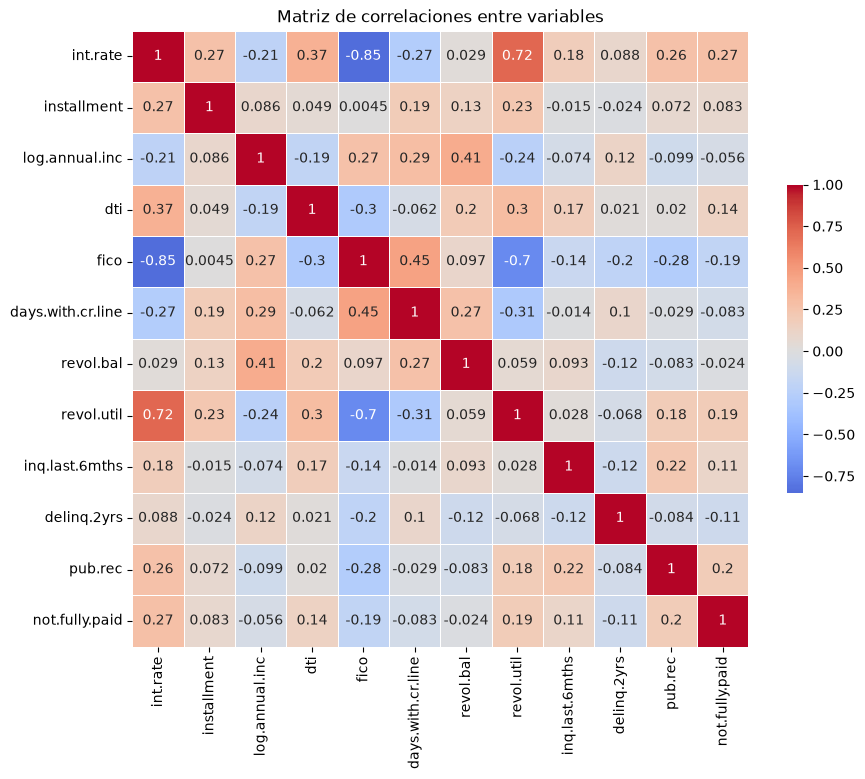

In [53]:
col_nums=data.select_dtypes(include=["int64","float64"])
col_nums.info()
col_nums=col_nums.drop(columns=['credit.policy','index'])
correlacion = col_nums.corr()
# Configuración del gráfico de correlación
plt.figure(figsize=(10, 8))

# Gráfico de correlaciones utilizando un mapa de calor
sns.heatmap(correlacion, annot=True, cmap='coolwarm', center=0, square=True, linewidths=.5, cbar_kws={"shrink": .5})

plt.title('Matriz de correlaciones entre variables')
plt.show()

In [ ]:
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     KFold, StratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV)

skf=StratifiedKFold(shuffle=5,random_state=42)